# Cancer Type Classification from RNA-Seq Gene Expression

**An end-to-end machine learning portfolio project (Scikit-learn)**



**Research question:** How well can conventional ML methods classify five cancer types using high-dimensional RNA-Seq expression features?

Dataset: **UCI Gene Expression Cancer RNA-Seq (ID 401)** — 801 tumor samples, 20,531 gene-expression features, five tumor classes (BRCA, KIRC, COAD, LUAD, PRAD). [UCI dataset](https://archive.ics.uci.edu/dataset/401/gene+expression+cancer+rna+seq) · [DOI:10.24432/C5R88H](https://doi.org/10.24432/C5R88H).

This is a **research/education** classification exercise, not a clinical diagnostic system. Features have anonymous identifiers (`gene_XX`), so biomarker claims require a reliable gene-ID mapping and further validation. Source values are already processed expression measurements—not raw FASTQ files; do not blindly apply a counts-based RNA-Seq normalization procedure.

**Important:** The notebook does **not** contain fabricated scores. Run all cells to generate your own measured results.

## 0 · Environment and imports


```bash
pip install -r requirements.txt
```

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import zipfile
import tarfile
import shutil
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay, adjusted_rand_score,
    silhouette_score)

RANDOM_STATE = 42
DATA_DIR = Path('data') / 'raw'
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

## 1 · Download the REAL UCI dataset

Note: Some UCI datasets are not reliably supported by `ucimlrepo.fetch_ucirepo()`, so we retrieve the official downloadable ZIP archive instead. Only the expected CSV members are extracted.

In [2]:
UCI_URL = 'https://archive.ics.uci.edu/static/public/401/gene%2Bexpression%2Bcancer%2Brna%2Bseq.zip'

def prepare_uci_files(directory=DATA_DIR):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    csv_file = directory / 'data.csv'
    label_file = directory / 'labels.csv'
    if csv_file.exists() and label_file.exists():
        print('Using existing local UCI CSV files.')
        return csv_file, label_file

    zip_path = directory / 'uci_rnaseq.zip'
    if not zip_path.exists():
        print('Downloading from UCI (~70 MB) ...')
        try:
            urlretrieve(UCI_URL, zip_path)
        except Exception as exc:
            zip_path.unlink(missing_ok=True)
            raise RuntimeError(
                'UCI download failed. Manually download the ZIP from the UCI dataset page, '
                'extract data.csv and labels.csv, and place them in data/raw/.'
            ) from exc

    if not zipfile.is_zipfile(zip_path):
        raise ValueError('Downloaded file is not a valid ZIP. Delete it and try again.')

    compressed_tar = directory / 'uci_rnaseq.tar.gz'
    try:
        with zipfile.ZipFile(zip_path) as archive:
            tar_names = [name for name in archive.namelist() if name.endswith('.tar.gz')]
            if len(tar_names) != 1:
                raise ValueError('Expected one .tar.gz file inside the official UCI ZIP.')
            with archive.open(tar_names[0]) as inp, compressed_tar.open('wb') as out:
                shutil.copyfileobj(inp, out)

        with tarfile.open(compressed_tar, mode='r:gz') as archive:
            for needed in ['data.csv', 'labels.csv']:
                matches = [member for member in archive.getmembers()
                           if member.isfile() and Path(member.name).name == needed]
                if len(matches) != 1:
                    raise ValueError(f'Expected one {needed} in the UCI archive.')
                source = archive.extractfile(matches[0])
                if source is None:
                    raise ValueError(f'Could not read {needed}')
                with source, (directory / needed).open('wb') as out:
                    shutil.copyfileobj(source, out)
    finally:
        compressed_tar.unlink(missing_ok=True)

    print('Ready:', csv_file, label_file)
    return csv_file, label_file

data_file, label_file = prepare_uci_files()

Ready: data\raw\data.csv data\raw\labels.csv


## 2 · Load and verify data



In [3]:
X = pd.read_csv(data_file, index_col=0).astype(np.float32)
labels_df = pd.read_csv(label_file, index_col=0)

if 'Class' not in labels_df.columns:
    raise ValueError(f'Expected a Class column. Found: {labels_df.columns.tolist()}')
if not X.index.is_unique or not labels_df.index.is_unique:
    raise ValueError('Sample identifiers must be unique in both files.')
if set(X.index) != set(labels_df.index):
    raise ValueError('The feature matrix and label file have different sample IDs.')

y = labels_df.loc[X.index, 'Class'].astype(str)
if X.isna().any().any() or not np.isfinite(X.to_numpy()).all():
    raise ValueError('Missing or infinite expression values detected; inspect the source data.')

print('Features:', X.shape)
print('Labels:', y.shape)
print('Cancer classes:', sorted(y.unique()))
print('\nClass balance:')
print(y.value_counts())
display(X.iloc[:3, :6])

Features: (801, 20531)
Labels: (801,)
Cancer classes: ['BRCA', 'COAD', 'KIRC', 'LUAD', 'PRAD']

Class balance:
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5
sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0
sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0
sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0


## 3 · Hold out the test set BEFORE detailed exploration


Train: (640, 20531) Test: (161, 20531)


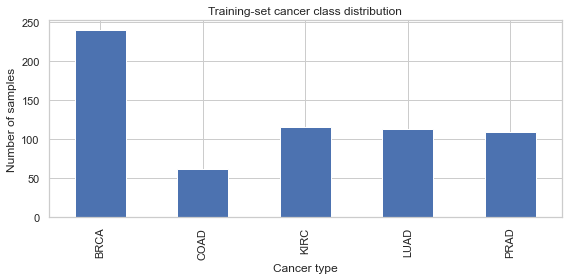

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)

fig, ax = plt.subplots(figsize=(8, 4))
y_train.value_counts().sort_index().plot(kind='bar', ax=ax)
ax.set(title='Training-set cancer class distribution', xlabel='Cancer type', ylabel='Number of samples')
plt.tight_layout()
plt.show()

## 4 · Create leakage-safe preprocessing Pipelines

We filter constant genes, select genes via an ANOVA-F statistic, scale features where appropriate, and train the classifier. **All learned preprocessing happens inside each CV training fold**. In the Random Forest pipeline, scaling is unnecessary.


In [5]:
def linear_pipeline(estimator, k=500):
    return Pipeline([
        ('variance', VarianceThreshold()),
        ('select', SelectKBest(score_func=f_classif, k=k)),
        ('scale', StandardScaler()),
        ('model', estimator),
    ])

def forest_pipeline(k=500):
    return Pipeline([
        ('variance', VarianceThreshold()),
        ('select', SelectKBest(score_func=f_classif, k=k)),
        ('model', RandomForestClassifier(
            n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1
        )),
    ])

models = {
    'Dummy majority': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': linear_pipeline(LogisticRegression(
        C=1.0, max_iter=2000, random_state=RANDOM_STATE
    )),
    'Linear SVM': linear_pipeline(SVC(
        C=1.0, kernel='linear'
    )),
    'RBF SVM': linear_pipeline(SVC(
        C=10, kernel='rbf', gamma='scale', random_state=RANDOM_STATE
    )),
    'Random Forest': forest_pipeline(),
}

cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

## 5 · Model comparison using cross-validation (TRAIN ONLY)


This can take several minutes depending on your computer.

In [6]:
results = []
for name, pipeline in models.items():
    scores = cross_validate(
        pipeline, X_train, y_train, cv=cv,
        scoring={'macro_f1': 'f1_macro', 'accuracy': 'accuracy'},
        n_jobs=1, error_score='raise'
    )
    results.append({
        'model': name,
        'cv_macro_f1_mean': scores['test_macro_f1'].mean(),
        'cv_macro_f1_std': scores['test_macro_f1'].std(),
        'cv_accuracy_mean': scores['test_accuracy'].mean(),
    })

baseline_table = pd.DataFrame(results).sort_values('cv_macro_f1_mean', ascending=False)
display(baseline_table.round(4))

,model,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean
1,Logistic Regression,0.9974,0.0026,0.9969
2,Linear SVM,0.9974,0.0026,0.9969
3,RBF SVM,0.9974,0.0026,0.9969
4,Random Forest,0.9961,0.0023,0.9953
0,Dummy majority,0.1091,0.0000,0.3750


## 6 · Tune hyperparameters without touching the test set

GridSearchCV chooses the number of retained genes and the Linear SVM's `C` parameter. This is a compact grid for learning purposes, not an exhaustive search.


In [7]:
search = GridSearchCV(
    estimator=linear_pipeline(SVC(kernel='linear')),
    param_grid={'select__k': [200, 500, 1000], 'model__C': [0.1, 1, 10]},
    scoring='f1_macro', cv=cv, n_jobs=1, refit=True,
    return_train_score=False, error_score='raise'
)
search.fit(X_train, y_train)
print('Best CV parameters:', search.best_params_)
print('Best CV macro-F1:', round(search.best_score_, 4))

tuned_row = pd.DataFrame([{
    'model': 'Tuned Linear SVM',
    'cv_macro_f1_mean': search.best_score_,
    'cv_macro_f1_std': np.nan,
    'cv_accuracy_mean': np.nan,
}])
comparison = pd.concat([baseline_table, tuned_row], ignore_index=True)
comparison = comparison.sort_values('cv_macro_f1_mean', ascending=False)
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / 'training_cv_comparison.csv', index=False)

Best CV parameters: {'model__C': 0.1, 'select__k': 1000}
Best CV macro-F1: 0.9987


,model,cv_macro_f1_mean,cv_macro_f1_std,cv_accuracy_mean
5,Tuned Linear SVM,0.9987,NaN,NaN
0,Logistic Regression,0.9974,0.0026,0.9969
1,Linear SVM,0.9974,0.0026,0.9969
2,RBF SVM,0.9974,0.0026,0.9969
3,Random Forest,0.9961,0.0023,0.9953
4,Dummy majority,0.1091,0.0000,0.3750


## 7 · Choose by TRAIN CV, then evaluate ONCE on TEST

To keep evaluation honest, the model is selected by training-set cross-validation only. We fit it on all of `X_train`, then generate a **single final hold-out test evaluation**. Don't keep tweaking the model based on test scores.


Chosen by train CV: Tuned Linear SVM


chosen_model              Tuned Linear SVM
test_accuracy                     0.993789
test_balanced_accuracy            0.992857
test_macro_f1                     0.994711
dtype: object


TEST classification report:
              precision    recall  f1-score   support

        BRCA       0.98      1.00      0.99        60
        COAD       1.00      1.00      1.00        16
        KIRC       1.00      1.00      1.00        30
        LUAD       1.00      0.96      0.98        28
        PRAD       1.00      1.00      1.00        27

    accuracy                           0.99       161
   macro avg       1.00      0.99      0.99       161
weighted avg       0.99      0.99      0.99       161



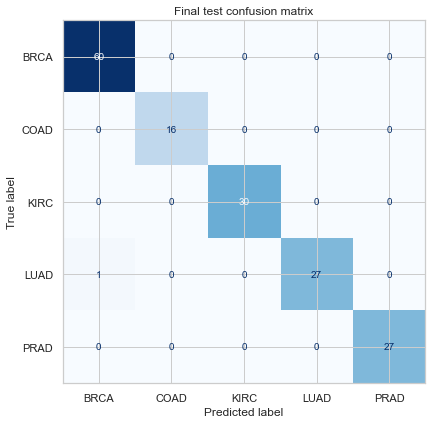

Saved results to: C:\Users\Sina\Desktop\CODES\Aurélien-Géron-Hands-On-Machine-Learning-with-Scikit-Learn-Keras-and-Tensorflow_-Concepts-Tools-and-Techniques-to-Build-Intelligent-Systems-O’Reilly-Media-2019\Cancer_RNASeq_ML_Project\outputs


In [8]:
chosen_name = comparison.iloc[0]['model']
if chosen_name == 'Tuned Linear SVM':
    final_model = search.best_estimator_  # already refitted on all training rows
else:
    final_model = clone(models[chosen_name]).fit(X_train, y_train)

pred_test = final_model.predict(X_test)
final_metrics = {
    'chosen_model': chosen_name,
    'test_accuracy': float(accuracy_score(y_test, pred_test)),
    'test_balanced_accuracy': float(balanced_accuracy_score(y_test, pred_test)),
    'test_macro_f1': float(f1_score(y_test, pred_test, average='macro')),
}
print('Chosen by train CV:', chosen_name)
display(pd.Series(final_metrics))
print('\nTEST classification report:')
print(classification_report(y_test, pred_test, zero_division=0))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, labels=sorted(y.unique()),
    cmap='Blues', values_format='d', ax=ax, colorbar=False
)
ax.set_title('Final test confusion matrix')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'test_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

pd.Series(final_metrics).to_csv(OUTPUT_DIR / 'final_test_metrics.csv', header=['value'])
joblib.dump(final_model, OUTPUT_DIR / 'final_model.joblib')
print('Saved results to:', OUTPUT_DIR.resolve())

## 8 · Optional extension: PCA and unsupervised clustering (TRAIN ONLY)


PCA plot shows **training samples**. An informative two-dimensional plot does not itself demonstrate clinical validity.

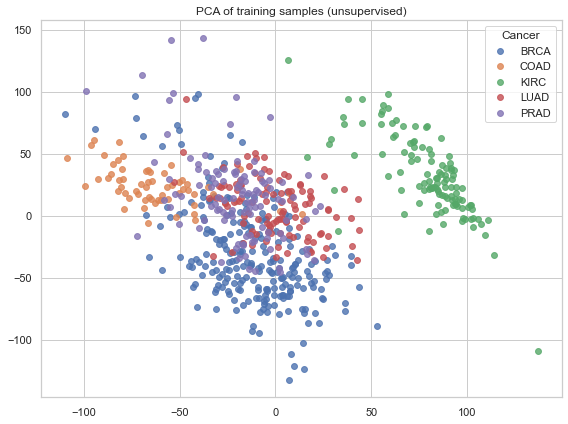

Two-PC explained variance fraction: 0.1942


In [9]:
pca_2d = Pipeline([
    ('variance', VarianceThreshold()),
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=2, svd_solver='randomized', random_state=RANDOM_STATE)),
])
coords = pca_2d.fit_transform(X_train)
plot_df = pd.DataFrame({'PC1': coords[:, 0], 'PC2': coords[:, 1], 'Cancer': y_train.to_numpy()})

fig, ax = plt.subplots(figsize=(8, 6))
for cancer, subset in plot_df.groupby('Cancer'):
    ax.scatter(subset['PC1'], subset['PC2'], label=cancer, alpha=0.8, s=35)
ax.legend(title='Cancer')
ax.set(title='PCA of training samples (unsupervised)')
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'training_pca.png', dpi=160, bbox_inches='tight')
plt.show()

print('Two-PC explained variance fraction:',
      round(float(pca_2d.named_steps['pca'].explained_variance_ratio_.sum()), 4))

In [10]:
cluster_preprocessing = Pipeline([
    ('variance', VarianceThreshold()),
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=30, svd_solver='randomized', random_state=RANDOM_STATE)),
])
Z_train = cluster_preprocessing.fit_transform(X_train)
k = y_train.nunique()  # prespecified known number of groups (five)
clusterers = {
    'K-Means': KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE),
    'Agglomerative': AgglomerativeClustering(n_clusters=k, linkage='ward'),
}
clustering_rows = []
for name, estimator in clusterers.items():
    cluster_ids = estimator.fit_predict(Z_train)
    clustering_rows.append({
        'method': name,
        'ARI_vs_known_labels': adjusted_rand_score(y_train, cluster_ids),
        'silhouette_score': silhouette_score(Z_train, cluster_ids),
    })
clustering_table = pd.DataFrame(clustering_rows)
display(clustering_table.round(4))
clustering_table.to_csv(OUTPUT_DIR / 'clustering_training_results.csv', index=False)

,method,ARI_vs_known_labels,silhouette_score
0,K-Means,0.7836,0.2597
1,Agglomerative,0.7688,0.2496


## 9 · Optional: examine genes selected by tuned Linear SVM

The model uses `gene_XXXX` anonymous features. Rankings are **predictive coefficients, not experimentally verified biomarkers**. Coefficients can be unstable under correlated predictors; a research follow-up should validate gene mapping, selection stability, batch effects, and external cohorts.

In [11]:
svm_pipe = search.best_estimator_
variance_mask = svm_pipe.named_steps['variance'].get_support()
remaining_genes = X_train.columns[variance_mask]
selected_mask = svm_pipe.named_steps['select'].get_support()
selected_genes = remaining_genes[selected_mask]
coef_strength = np.abs(svm_pipe.named_steps['model'].coef_).mean(axis=0)
gene_ranking = pd.DataFrame({
    'anonymous_gene': selected_genes,
    'mean_abs_linear_svm_coefficient': coef_strength,
}).sort_values('mean_abs_linear_svm_coefficient', ascending=False)
display(gene_ranking.head(15))
gene_ranking.to_csv(OUTPUT_DIR / 'tuned_svm_feature_ranking.csv', index=False)

,anonymous_gene,mean_abs_linear_svm_coefficient
428,gene_7623,0.005028
555,gene_10460,0.004300
308,gene_5578,0.003935
675,gene_13517,0.003905
607,gene_11903,0.003901
767,gene_15895,0.003900
680,gene_13631,0.003858
445,gene_8004,0.003803
525,gene_9706,0.003752
880,gene_17771,0.003745


## 10 · Research reflection and portfolio checklist

Complete this section **after running** the notebook:

1. **Data:** Describe class frequencies and sample/feature ratio (high-dimensional *p >> n*).
2. **Validation:** Explain why the test set is locked away and why feature selection stays within the CV pipeline.
3. **Results:** Paste the actual CV model comparison and final holdout test metrics (do not invent them).
4. **Biology:** Explain the labels: `BRCA` breast, `KIRC` kidney clear cell, `COAD` colon adenocarcinoma, `LUAD` lung adenocarcinoma, `PRAD` prostate adenocarcinoma.
5. **Limitations:** This is a small, curated, processed tumor-type dataset. It does not measure clinical usefulness, early detection, performance on healthy samples, domain shift, or cross-institution generalization. Gene identities are anonymized and batch effects are not addressed here.
6. **Follow-up for applications:** External validation on a compatible GEO/TCGA cohort; meaningful gene annotation; differential-expression methods used where appropriate; more rigorous biomarker discovery and selection-stability analysis.


### Citation

Fiorini, S. (2016). *gene expression cancer RNA-Seq* [Dataset]. UCI Machine Learning Repository. [https://doi.org/10.24432/C5R88H](https://doi.org/10.24432/C5R88H). License: CC BY 4.0.